<table>
    <tr>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="300"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Modelos </p>Conceptos </p> Regresión     </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Machine Learning </p></tp>
            <tp><p style="font-size:115%;text-align:center">Diplomado 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>

# <FONT SIZE=5 COLOR="purple"> 1. Concepto de Regresión </FONT>

**Modelo de regresión:** es el modelo en el que se busca establecer la relación entre un cierto número de características y una variable objetivo continua. Es decir, la relación entre la variable dependiente $y$ y las variables predictoras $x_1, x_2 , \dots , x_n$.

En los modelos de regresión no se predice una clase, sino un valor continuo.

Anteriormente habíamos examinado los diferentes métodos de clasificación, conocidos como *classifier*. En esta sección revisaremos las instrucciónes para generar las regresiones (regressor).

https://keepcoding.io/blog/como-funciona-el-k-nn-en-regresion/

https://fhernanb.github.io/libro_mod_pred/arb-de-regre.html

https://www.cienciadedatos.net/documentos/py07_arboles_decision_python.html

https://towardsdatascience.com/random-forest-regression-5f605132d19d

## <FONT SIZE=4 COLOR="blue"> 1.1 k-Nearest Neighbors (kNN) para regresión </FONT>

En lugar de clasificar una muestra, el kNN para regresión predice un valor numérico, como sigue:

1. **Identificación de los vecinos más cercanos**: Dado un nuevo punto de datos, el algoritmo busca los **k** puntos más cercanos en el espacio de características (según una medida de distancia como la euclidiana).
   
2. **Cálculo del valor predicho**: El valor de salida para el punto nuevo se calcula promediando los valores de las etiquetas de los **k** vecinos más cercanos. Es decir:
$$   \hat{y} = \frac{1}{k} \sum_{i=1}^{k} y_i $$
   
donde $ y_i $ son las etiquetas de los k-vecinos más cercanos.

3. **Suavizado del resultado**: Como resultado, el valor de salida es continuo, lo que convierte al kNN en una técnica válida para regresión.

## <FONT SIZE=4 COLOR="blue"> 1.2 Árboles de decisión para regresión </FONT>

En los árboles de decisión para regresión, el procedimiento también cambia respecto al de clasificación:

1. **División del conjunto de datos**: El árbol se construye dividiendo el conjunto de datos en ramas con base en los valores de las características. Sin embargo, en lugar de buscar divisiones que maximicen la ganancia de información o el índice de Gini (usado en clasificación), en regresión se busca minimizar la **varianza** o el **error cuadrático medio** (MSE, por sus siglas en inglés).

2. **Predicción**: Una vez que el árbol está entrenado, la predicción para un nuevo punto de datos se realiza navegando por el árbol desde la raíz hasta una hoja. El valor en la hoja no es una clase, sino un valor promedio de las etiquetas de los datos que caen en esa hoja.

3. **Criterio de división**: Para cada nodo, el árbol selecciona la característica y el punto de división que minimicen la suma del error cuadrático medio en los subconjuntos hijos.

El modelo final hace una predicción basada en los valores promedio de los datos en los nodos terminales, obteniendo así una predicción numérica.

### Comparación:
- En **kNN para regresión**, la predicción es un promedio de los vecinos cercanos.
- En **árboles de decisión para regresión**, la predicción es el valor promedio de los datos en las hojas del árbol.

## <FONT SIZE=4 COLOR="blue"> 1.3 Error Cuadrático Medio </FONT>

El **Error Cuadrático Medio** (MSE, por sus siglas en inglés de *Mean Squared Error*) es una medida de la calidad de un modelo de regresión que cuantifica la diferencia promedio entre los valores predichos por el modelo y los valores reales de las observaciones.

El MSE es especialmente útil para medir el rendimiento en problemas de regresión, ya que da una idea de cuán lejos están las predicciones del modelo respecto a los valores reales en promedio.

Este valor se define como el promedio de los cuadrados de las diferencias entre los valores reales $y_i $ y los valores predichos $\hat{y}_i$:

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$

donde:

- $n$ es el número total de ejemplos en el conjunto de datos.

- $y_i$ es el valor real para la observación $i$.

- $\hat{y}_i$ es el valor predicho por el modelo para la observación $i$.

**Explicación de la fórmula**

a. **Diferencia**: Para cada punto de datos, calculamos la diferencia entre el valor real $y_i$ y el valor predicho $\hat{y}_i$.
   
b. **Cuadrado de la diferencia**: Elevamos al cuadrado cada una de estas diferencias. Esto garantiza que los errores positivos y negativos no se cancelen entre sí y penaliza más los errores grandes.

c. **Promedio**: Sumamos los cuadrados de las diferencias y dividimos por el número total de puntos de datos para obtener el promedio de esos errores cuadráticos.

El MSE siempre es positivo y un valor más bajo de MSE indica un mejor ajuste del modelo a los datos.


<FONT SIZE=5 COLOR="blue"> Librería de trabajo </FONT>

In [1]:
# Para gráficos y data.frames
import pandas as pd
import numpy  as np

# librerías para graficar
import plotly.express     as px
import matplotlib.pyplot  as plt
import seaborn            as sns


# Dividir los datos entrenamiento y prueba
from sklearn.model_selection     import train_test_split
from sklearn.feature_selection   import RFE

# Para preprocesamiento: escalador
from sklearn.preprocessing       import StandardScaler

# Modelo de regresión
from sklearn.linear_model        import LinearRegression
from sklearn.neighbors           import KNeighborsRegressor
from sklearn.tree                import DecisionTreeRegressor

from sklearn.ensemble            import RandomForestRegressor
from sklearn.svm                 import SVR
# Métricas
from sklearn                     import metrics
from sklearn.metrics             import mean_squared_error, r2_score

<FONT SIZE=5 COLOR="blue"> Idea intuitiva gráfica </FONT>

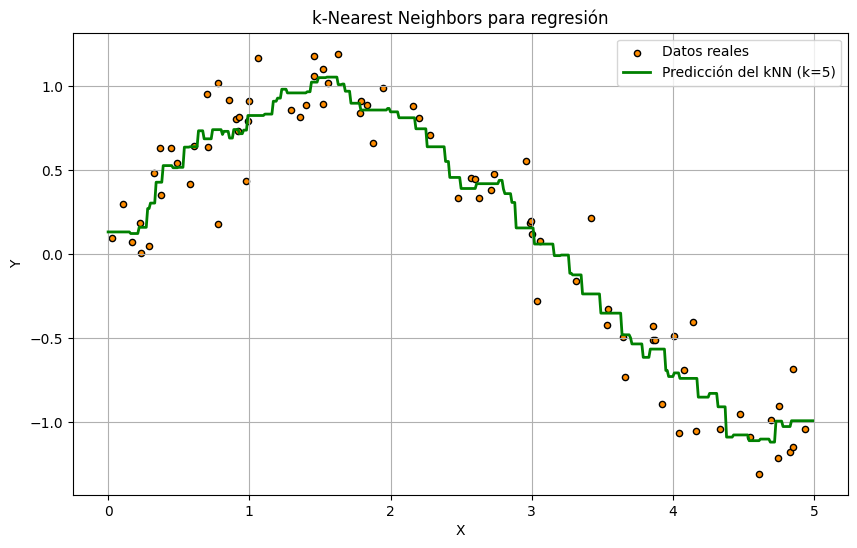

In [ ]:
# @title
# gráfico para knn
from sklearn.neighbors import KNeighborsRegressor

# Generamos datos de ejemplo
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.randn(80) * 0.2

# Creamos un modelo de kNN para regresión
knn_regressor = KNeighborsRegressor(n_neighbors=5)
knn_regressor.fit(X, y)

# Predicciones
X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_knn_pred = knn_regressor.predict(X_test)

# Gráfica
plt.figure(figsize=(10, 6))
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="Datos reales")
plt.plot(X_test, y_knn_pred, color="green", label="Predicción del kNN (k=5)", linewidth=2)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("k-Nearest Neighbors para regresión")
plt.legend()
plt.grid(True)

plt.show()


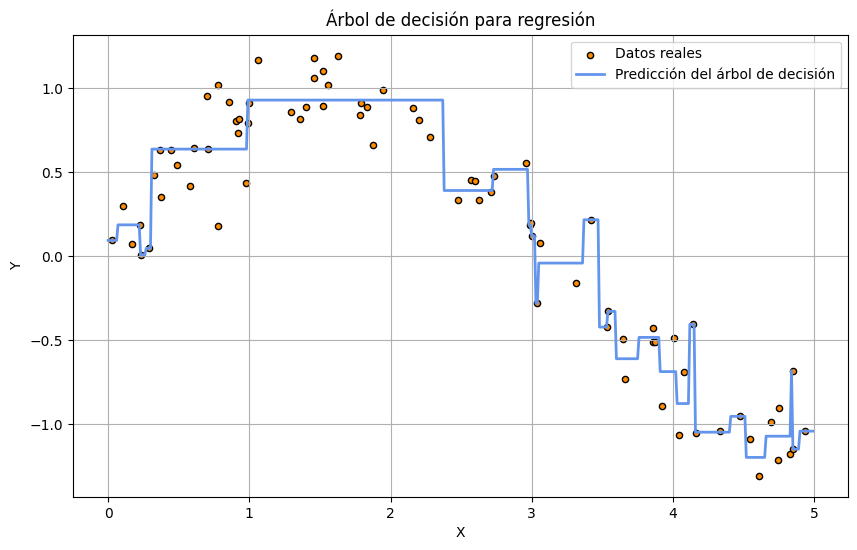

In [ ]:
# @title
# gráfico para árboles de decisión
import matplotlib.pyplot as plt
import numpy as np
from  sklearn.tree import DecisionTreeRegressor

# Generamos datos de ejemplo
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.randn(80) * 0.2

# Ajustamos un árbol de decisión para regresión
tree_regressor = DecisionTreeRegressor(max_depth=5)
tree_regressor.fit(X, y)

# Predicciones
X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_pred = tree_regressor.predict(X_test)

# Gráfica
plt.figure(figsize=(10, 6))
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="Datos reales")
plt.plot(X_test, y_pred, color="cornflowerblue", label="Predicción del árbol de decisión", linewidth=2)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Árbol de decisión para regresión")
plt.legend()
plt.grid(True)

plt.show()

# <FONT SIZE=5 COLOR="purple"> 2. Ejemplo 1 de Regresión (calorias) </FONT>

Vamos a considerar los datos de kaggle

https://www.kaggle.com/code/samtam22/exercise-and-calorie-burning-data-analysis

que contienen las siguientes variables.

- **User_Id** : Identificador único para cada individuo del conjunto de datos.

  - Sirve para vincular diferentes registros del mismo usuario (por ejemplo, de dos datasets: uno de ejercicios y otro de calorías).

- **Gender**: Género del usuario.  En los datos suelen estar codificados como: male = 0, female = 1, o viceversa

- **Age** : Edad del usuario en años.

- **Height**: Estatura del usuario, normalmente expresada en centímetros (cm)

- **Weight** : Peso del usuario en kilogramos (kg).

- **Duration**:  Duración del ejercicio o actividad física, generalmente expresada en minutos

- **Heart_Rate**: Frecuencia cardíaca promedio durante el ejercicio, medida en pulsos por minuto (bpm)

- **Body_Temp**: Temperatura corporal promedio durante la actividad, en grados Celsius (°C)

- **Calories**: Calorías quemadas estimadas durante el ejercicio.

Es la variable objetivo en modelos que predicen gasto energético en base a los factores anteriores

In [2]:
calorias = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/calories.csv")
calorias

,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0
...,...,...
14995,15644082,45.0
14996,17212577,23.0
14997,17271188,75.0
14998,18643037,11.0


In [3]:
ejercicio = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/exercise.csv")
ejercicio

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...,...
14995,15644082,female,20,193.0,86.0,11.0,92.0,40.4
14996,17212577,female,27,165.0,65.0,6.0,85.0,39.2
14997,17271188,female,43,159.0,58.0,16.0,90.0,40.1
14998,18643037,male,78,193.0,97.0,2.0,84.0,38.3


Vamos a fusionar los datos

In [5]:
# pegar los dos dataframes
datos = pd.concat([calorias, ejercicio], axis=1)
datos

,User_ID,Calories,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,231.0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,66.0,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,26.0,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,71.0,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,35.0,17771927,female,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...,...,...,...
14995,15644082,45.0,15644082,female,20,193.0,86.0,11.0,92.0,40.4
14996,17212577,23.0,17212577,female,27,165.0,65.0,6.0,85.0,39.2
14997,17271188,75.0,17271188,female,43,159.0,58.0,16.0,90.0,40.1
14998,18643037,11.0,18643037,male,78,193.0,97.0,2.0,84.0,38.3


Vamos a eliminar la variable User_ID

In [6]:
# eliminar User_ID
datos = datos.drop('User_ID', axis=1)
datos

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,male,68,190.0,94.0,29.0,105.0,40.8
1,66.0,female,20,166.0,60.0,14.0,94.0,40.3
2,26.0,male,69,179.0,79.0,5.0,88.0,38.7
3,71.0,female,34,179.0,71.0,13.0,100.0,40.5
4,35.0,female,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...,...
14995,45.0,female,20,193.0,86.0,11.0,92.0,40.4
14996,23.0,female,27,165.0,65.0,6.0,85.0,39.2
14997,75.0,female,43,159.0,58.0,16.0,90.0,40.1
14998,11.0,male,78,193.0,97.0,2.0,84.0,38.3


Hacemos una pequeña exploración de los datos

In [7]:
# cabeza de los datos
datos.head()

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,male,68,190.0,94.0,29.0,105.0,40.8
1,66.0,female,20,166.0,60.0,14.0,94.0,40.3
2,26.0,male,69,179.0,79.0,5.0,88.0,38.7
3,71.0,female,34,179.0,71.0,13.0,100.0,40.5
4,35.0,female,27,154.0,58.0,10.0,81.0,39.8


In [8]:
# tamaño de los datos
datos.shape

(15000, 8)

In [9]:
# variables de los datos
datos.columns

Index(['Calories', 'Gender', 'Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp'],
      dtype='object')

In [10]:
# información de los datos
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Calories    15000 non-null  float64
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 937.6+ KB


In [ ]:
px.box(datos.Height)

In [ ]:
# estadística de los datos
datos.describe()

,Calories,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,89.539533,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453
std,62.456978,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230
min,1.000000,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000
25%,35.000000,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000
50%,79.000000,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000
75%,138.000000,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000
max,314.000000,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000


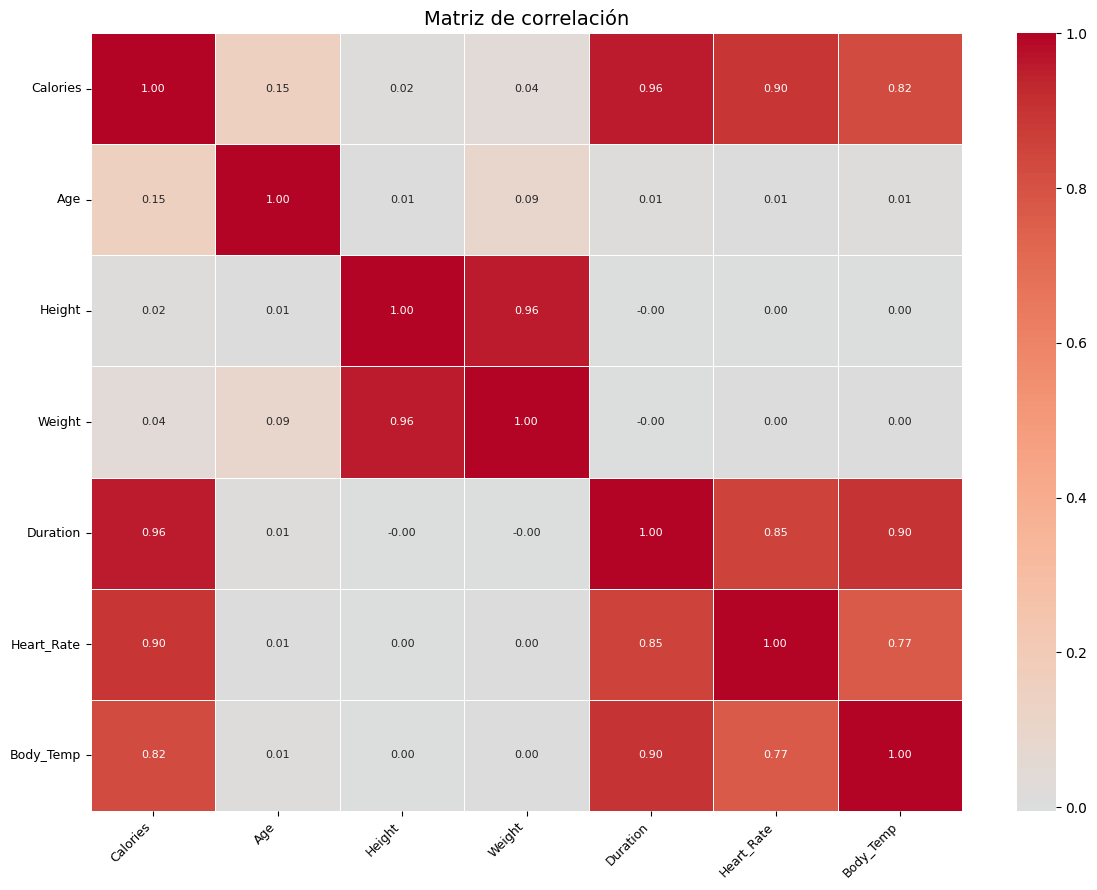

In [12]:
# diagrama de correlación
num_cols = datos.select_dtypes(include=["number"])
corr = num_cols.corr()
plt.figure(figsize=(12, 9))

# Mapa de correlación
sns.heatmap(corr,              # matriz de correlaciones
            annot=True,                   # para colocar números adentro (correlaciones)
            fmt=".2f",                    # formato de los números
            cmap="coolwarm",              # colores frio-caliente
            center=0,                     # centro de la escala
            annot_kws={"size": 8},        # tamaño de los números
            linewidths=0.5
)

# Tamaño de etiquetas
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.title("Matriz de correlación", fontsize=14)

plt.tight_layout()
plt.show()

In [13]:
# gender convertir a 1 y 0
datos.Gender.replace({"male":1, "female":0}, inplace= True)


/tmp/ipykernel_6006/581747291.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  datos.Gender.replace({"male":1, "female":0}, inplace= True)
/tmp/ipykernel_6006/581747291.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  datos.Gender.replace({"male":1, "female":0}, inplace= True)


In [14]:
datos.head()

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,1,68,190.0,94.0,29.0,105.0,40.8
1,66.0,0,20,166.0,60.0,14.0,94.0,40.3
2,26.0,1,69,179.0,79.0,5.0,88.0,38.7
3,71.0,0,34,179.0,71.0,13.0,100.0,40.5
4,35.0,0,27,154.0,58.0,10.0,81.0,39.8


In [15]:
# convertir gender a categórica
datos.Gender = datos.Gender.astype("category")

In [ ]:
datos.head()

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,1,68,190.0,94.0,29.0,105.0,40.8
1,66.0,0,20,166.0,60.0,14.0,94.0,40.3
2,26.0,1,69,179.0,79.0,5.0,88.0,38.7
3,71.0,0,34,179.0,71.0,13.0,100.0,40.5
4,35.0,0,27,154.0,58.0,10.0,81.0,39.8


In [16]:
# seleccionar las variables para los modelos
X = datos.drop("Calories", axis=1)
y = datos["Calories"]

# seleccionar los conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)

# Escalar los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
X_train_scaled

array([[ 1.00719253, -0.33729461,  0.32323185, ..., -1.02188864,
        -1.51737651, -0.67103106],
       [ 1.00719253, -1.16332224,  1.44792406, ...,  1.26666332,
         1.52242538,  0.61448958],
       [ 1.00719253, -0.57330251,  0.46381838, ..., -0.41963812,
        -0.78363123,  0.10028132],
       ...,
       [ 1.00719253,  0.84274485,  1.02616448, ..., -0.90143854,
        -0.57398972, -0.67103106],
       [ 1.00719253, -0.45529856, -0.02823446, ..., -0.41963812,
         0.15975557,  0.22883339],
       [ 1.00719253, -0.98631632,  0.53411164, ...,  0.06216229,
        -0.46916896,  0.61448958]])

## <FONT SIZE=5 COLOR="magenta"> 2.1 Modelo con KNN </FONT>

In [18]:
# librería
from sklearn.neighbors import KNeighborsRegressor
# modelo
KNN = KNeighborsRegressor(n_neighbors=5)
# entrenamiento
KNN.fit(X_train_scaled, y_train)
# predicciones
y_pred_knn = KNN.predict(X_test_scaled)
# métricas
print("R2",r2_score(y_test, y_pred_knn))                             # coeficiente de determinación
print('MSE', mean_squared_error(y_test, y_pred_knn))                 # error cuadrático medio
print('RMSE', np.sqrt(mean_squared_error(y_test,y_pred_knn)))        # raíz error cuadrático medio

R2 0.993517709356327
MSE 26.16117333333333
RMSE 5.114799442141728


In [19]:
datos.Calories.describe()

,Calories
count,15000.000000
mean,89.539533
std,62.456978
min,1.000000
25%,35.000000
50%,79.000000
75%,138.000000
max,314.000000


In [20]:
# calcular métricas básicas
rmse = np.sqrt(mean_squared_error(y_test, y_pred_knn))
# estadísticas de la variable objetivo
y_mean = datos["Calories"].mean()
y_std = datos["Calories"].std()
y_min = datos["Calories"].min()
y_max = datos["Calories"].max()
y_range = y_max - y_min

# comparaciones relativas
rmse_vs_mean = rmse / y_mean
rmse_vs_std = rmse / y_std
rmse_vs_range = rmse / y_range

# imprimir resultados
print(f"RMSE: {rmse:.2f}")
print(f"RMSE vs media: {rmse_vs_mean:.2%}")
print(f"RMSE vs desviación estándar: {rmse_vs_std:.2%}")
print(f"RMSE vs rango: {rmse_vs_range:.2%}")

RMSE: 5.11
RMSE vs media: 5.71%
RMSE vs desviación estándar: 8.19%
RMSE vs rango: 1.63%


## <FONT SIZE=5 COLOR="magenta"> 2.2 Modelo con Regresión Lineal </FONT>

In [21]:
# modelo de regresión lineal
modelo = LinearRegression()
# entrenamiento
modelo.fit(X_train_scaled,y_train)
# predicción
y_pred_linear= modelo.predict(X_test_scaled)
# evaluación del modelo
print("R2",r2_score(y_test, y_pred_linear))                             # coeficiente de determinación
print('MSE', mean_squared_error(y_test, y_pred_linear))                 # error cuadrático medio
print('RMSE', np.sqrt(mean_squared_error(y_test,y_pred_linear)))        # raíz error cuadrático medio

R2 0.9672937151257295
MSE 131.995745750817
RMSE 11.48894014915288


In [22]:
# calcular métricas básicas
rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
# estadísticas de la variable objetivo
y_mean = datos["Calories"].mean()
y_std = datos["Calories"].std()
y_min = datos["Calories"].min()
y_max = datos["Calories"].max()
y_range = y_max - y_min

# comparaciones relativas
rmse_vs_mean = rmse / y_mean
rmse_vs_std = rmse / y_std
rmse_vs_range = rmse / y_range

# imprimir resultados
print(f"RMSE: {rmse:.2f}")
print(f"RMSE vs media: {rmse_vs_mean:.2%}")
print(f"RMSE vs desviación estándar: {rmse_vs_std:.2%}")
print(f"RMSE vs rango: {rmse_vs_range:.2%}")

RMSE: 11.49
RMSE vs media: 12.83%
RMSE vs desviación estándar: 18.39%
RMSE vs rango: 3.67%


## <FONT SIZE=5 COLOR="magenta"> 2.3 Modelo con árboles de Decisión </FONT>

Vamos a trabajar con los datos sin escalar

In [23]:
# modelo
Tree_reg = DecisionTreeRegressor(random_state= 0)
# entrenamiento
Tree_reg.fit(X_train, y_train)
# predicción
y_pred_tree = Tree_reg.predict(X_test)
# evaluación del modelo
print("R2",r2_score(y_test, y_pred_tree))                             # coeficiente de determinación
print('MSE', mean_squared_error(y_test, y_pred_tree))                 # error cuadrático medio
print('RMSE', np.sqrt(mean_squared_error(y_test,y_pred_tree)))        # raíz error cuadrático medio

R2 0.9930967692071127
MSE 27.86
RMSE 5.278257288158659


In [ ]:
# calcular métricas básicas
rmse = np.sqrt(mean_squared_error(y_test, y_pred_tree))
# estadísticas de la variable objetivo
y_mean = datos["Calories"].mean()
y_std = datos["Calories"].std()
y_min = datos["Calories"].min()
y_max = datos["Calories"].max()
y_range = y_max - y_min

# comparaciones relativas
rmse_vs_mean = rmse / y_mean
rmse_vs_std = rmse / y_std
rmse_vs_range = rmse / y_range

# imprimir resultados
print(f"RMSE: {rmse:.2f}")
print(f"RMSE vs media: {rmse_vs_mean:.2%}")
print(f"RMSE vs desviación estándar: {rmse_vs_std:.2%}")
print(f"RMSE vs rango: {rmse_vs_range:.2%}")

RMSE: 5.28
RMSE vs media: 5.89%
RMSE vs desviación estándar: 8.45%
RMSE vs rango: 1.69%


In [ ]:
print(f"Profundidad del árbol: {Tree_reg.get_depth()}")
print(f"Número de nodos terminales: {Tree_reg.get_n_leaves()}")

Profundidad del árbol: 21
Número de nodos terminales: 8842


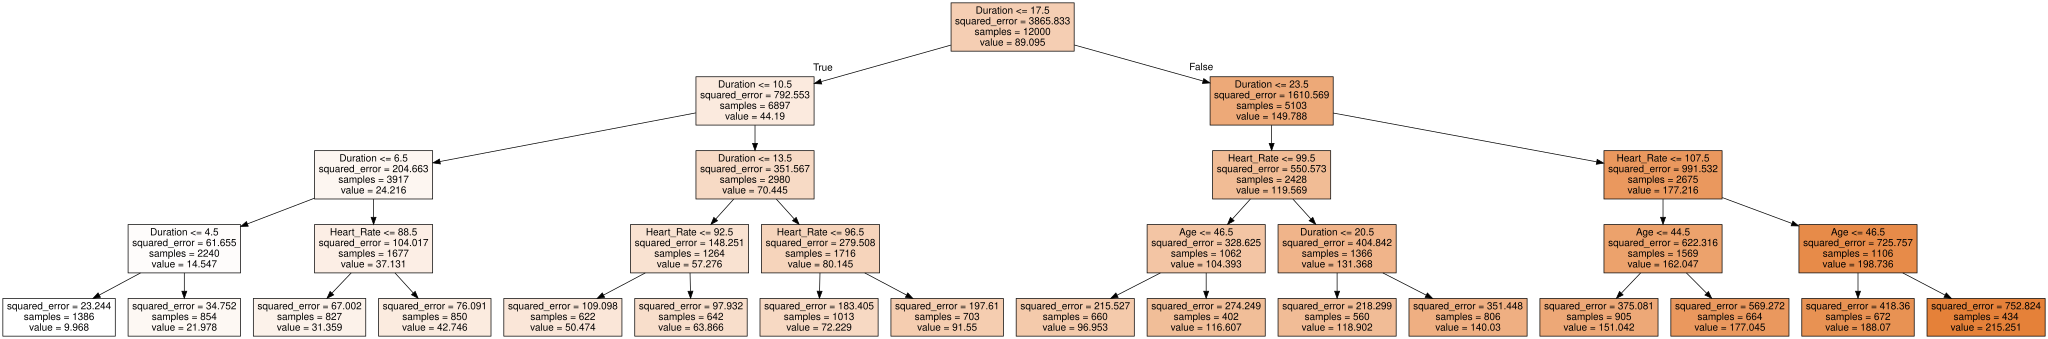

In [ ]:
from graphviz                 import Source
from sklearn.tree             import export_graphviz
Tree_reg2 = DecisionTreeRegressor(max_depth= 4,
                                  random_state= 0)
Tree_reg2.fit(X_train, y_train)
# Generamos el árbol
dot_data = export_graphviz(Tree_reg2,                                 # modelo
                           feature_names = X_train.columns,            # columnas de entrenamiento
                           filled=True)                                # colores del árbol (relleno)
Source(dot_data, format="png")

In [ ]:
# variables más importantes en árboles de decisión
importances = Tree_reg.feature_importances_
importances

array([7.52966015e-03, 2.56176575e-02, 1.14271880e-03, 2.54906126e-03,
       9.13769905e-01, 4.90308266e-02, 3.60170351e-04])

In [ ]:
print("Importancia de los predictores en el modelo")
print("-------------------------------------------")
importancia_predictores = pd.DataFrame(
    {'predictor': X_train.columns.tolist(),
     'importancia': Tree_reg.feature_importances_}
)
importancia_predictores.sort_values('importancia', ascending=False)

Importancia de los predictores en el modelo
-------------------------------------------


,predictor,importancia
4,Duration,0.913770
5,Heart_Rate,0.049031
1,Age,0.025618
0,Gender,0.007530
3,Weight,0.002549
2,Height,0.001143
6,Body_Temp,0.000360


# <FONT SIZE=5 COLOR="purple"> 3. Ejemplo 2 Regresión (ventas) </FONT>

Vamos a considerar los siguientes datos relacionados con la inversión en publicidad en diferentes medios y las ventas.

El objetivo es hacer un modelo de regresión lineal múltiple para predecir las ventas en función de las variables de pauta publicitaria en diferentes medios.

Se describen las variables independientes: TV, Radio Newpaper y la variable dependiente Sales.

Valor de etiqueta o variable objetivo dependiente(ventas): que significa el volumen de ventas del producto correspondiente

Las variables independientes: (TV, Radio, Periódico, WEB):

TV: para un solo producto en un mercado determinado, el costo de la publicidad en TV (en miles) Radio: costos de publicidad invertidos en medios de difusión Periódico: costos publicitarios para medios periodísticos.

## <FONT SIZE=4 COLOR="green"> 3.1 Carga y exploración de los datos</FONT>

In [ ]:
ventas = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/Ventas.csv", sep = ";" , decimal = "," )
ventas

In [ ]:
# eliminar la primera columna
ventas = ventas.drop(ventas.columns[0],
                     axis=1)

In [ ]:
ventas.head()

In [ ]:
corr = ventas.corr()
corr

In [ ]:
# matriz de correlación
sns.heatmap(corr, annot = True,
            yticklabels=corr.columns,
            xticklabels=corr.columns)

Primero, seleccionamos las variables predictoras y la variable objetivo

In [ ]:
# variable objetivo
y = ventas['Sales']
# variables predictoras
X = ventas.drop('Sales', axis=1)

In [ ]:
# conjunto de entrenamiento y prueba
X_train,X_test,y_train,y_test=train_test_split(X,
                                               y,
                                               train_size=0.70,
                                               random_state=123)

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## <FONT SIZE=4 COLOR="green"> 3.2 Modelo con KNN </FONT>

In [ ]:
# librería
from sklearn.neighbors import KNeighborsRegressor
# modelo
KNN = KNeighborsRegressor(n_neighbors=5)
# entrenamiento
KNN.fit(X_train_s, y_train)
# predicciones
y_pred = KNN.predict(X_test_s)
# métricas
print("R2",r2_score(y_test, y_pred))                             # coeficiente de determinación
print('MSE', mean_squared_error(y_test, y_pred))                 # error cuadrático medio
print('RMSE', np.sqrt(mean_squared_error(y_test,y_pred)))        # raíz error cuadrático medio

## <FONT SIZE=4 COLOR="green"> 3.3 Modelo con Árboles de Decisión </FONT>


In [ ]:
# modelo
Tree_reg = DecisionTreeRegressor(random_state= 0)
# entrenamiento
Tree_reg.fit(X_train_s, y_train)
# predicción
y_pred = Tree_reg.predict(X_test_s)
# evaluación del modelo
print("R2",r2_score(y_test, y_pred))                             # coeficiente de determinación
print('MSE', mean_squared_error(y_test, y_pred))                 # error cuadrático medio
print('RMSE', np.sqrt(mean_squared_error(y_test,y_pred)))        # raíz error cuadrático medio

## <FONT SIZE=4 COLOR="green"> 3.4 Modelo con Regresión Múltiple </FONT>

In [ ]:
# modelo de regresión lineal
modelo = LinearRegression()
# entrenamiento
modelo.fit(X_train_s,y_train)
# predicción
y_pred = modelo.predict(X_test_s)
# evaluación del modelo
print("R2",r2_score(y_test, y_pred))                             # coeficiente de determinación
print('MSE', mean_squared_error(y_test, y_pred))                 # error cuadrático medio
print('RMSE', np.sqrt(mean_squared_error(y_test,y_pred)))        # raíz error cuadrático medio